# Modelo Random Forest — Wine Quality Classification

## Objetivo
Desenvolver um modelo de classificação para prever se um vinho pertence à classe de alta qualidade ou à classe de baixa/média qualidade.

## Definição do alvo
- Alta qualidade: quality >= 7
- Baixa/média qualidade: quality < 7

## Metodologia
Preparação dos dados, treinamento, avaliação, ajuste de hiperparâmetros e interpretação dos resultados.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    PrecisionRecallDisplay
)

SEED = 42

In [3]:
df = pd.read_csv(r"C:\Users\Isabela Pucci\OneDrive\Documentos\GitHub\wine-quality-classification-ml\data\WineQT.csv")

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [4]:
#preparando os dados para o modelo, criando a classe de qualidade

df["quality_class"] = (df["quality"] >= 7).astype(int)

df[["quality", "quality_class"]].head(10)

,quality,quality_class
0,5,0
1,5,0
2,5,0
3,6,0
4,5,0
5,5,0
6,5,0
7,7,1
8,7,1
9,5,0


In [5]:
# vimos o balanceamento no pré-processamento, sabendo disso
# separando a variável alvo
X = df.drop(columns=["quality", "quality_class", "Id"], errors="ignore")

y = df["quality_class"]

print("Quantidade de features:", X.shape[1])
print("\nFeatures utilizadas:")
print(X.columns.tolist())

print("\nQuantidade de registros:", len(y))

Quantidade de features: 11

Features utilizadas:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Quantidade de registros: 1143


In [6]:
# também vimos que existem 125 registros iguais na nossa base
# Preservar a base original
df_original = df.copy()

# Definir as características físico-químicas usadas para identificar perfis iguais
features = [col for col in df.columns if col not in ["Id", "quality", "quality_class"]]

# Identificar perfis repetidos
colunas_comparacao = features

duplicados = df[df.duplicated(subset=colunas_comparacao, keep=False)].copy()

print("Linhas envolvidas em perfis repetidos:", len(duplicados))
print("Combinações repetidas:", df.duplicated(subset=colunas_comparacao).sum())

# Verificar se perfis iguais possuem notas de qualidade diferentes
notas_por_perfil = df.groupby(colunas_comparacao)["quality"].nunique()
perfis_com_notas_diferentes = notas_por_perfil[notas_por_perfil > 1]

print("Perfis com notas de qualidade diferentes:", len(perfis_com_notas_diferentes))

# Guardar os registros retirados para consulta
df_retirados = df.loc[df.duplicated(subset=colunas_comparacao, keep="first")].copy()

# Manter a primeira ocorrência de cada perfil
df_limpo = df.drop_duplicates(subset=colunas_comparacao, keep="first").copy()

print("Linhas antes:", len(df))
print("Linhas depois:", len(df_limpo))
print("Linhas retiradas:", len(df) - len(df_limpo))

# Validar a remoção
assert not df_limpo.duplicated(subset=colunas_comparacao).any()


Linhas envolvidas em perfis repetidos: 239
Combinações repetidas: 125
Perfis com notas de qualidade diferentes: 0
Linhas antes: 1143
Linhas depois: 1018
Linhas retiradas: 125


In [7]:

print("Perfis com notas de qualidade diferentes:", len(perfis_com_notas_diferentes))

Perfis com notas de qualidade diferentes: 0


In [8]:
X = df_limpo.drop(columns=["quality", "quality_class", "Id"], errors="ignore")

y = df_limpo["quality_class"]

print("Quantidade de features:", X.shape[1])
print("\nFeatures utilizadas:")
print(X.columns.tolist())

print("\nQuantidade de registros:", len(y))

Quantidade de features: 11

Features utilizadas:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Quantidade de registros: 1018


In [13]:
from pathlib import Path

PASTA_RESULTADOS = Path(r"C:\Users\Isabela Pucci\OneDrive\Documentos\GitHub\wine-quality-classification-ml\etapa_3\resultados")

X_train = pd.read_csv(PASTA_RESULTADOS / "X_train.csv")
X_test = pd.read_csv(PASTA_RESULTADOS / "X_test.csv")
y_train = pd.read_csv(PASTA_RESULTADOS / "y_train.csv").squeeze("columns")
y_test = pd.read_csv(PASTA_RESULTADOS / "y_test.csv").squeeze("columns")


print("Registros de treino:", len(X_train))
print("Registros de teste:", len(X_test))

print("\nProporção da classe alta:")
print("Treino:", round(y_train.mean() * 100, 2), "%")
print("Teste:", round(y_test.mean() * 100, 2), "%")

Registros de treino: 814
Registros de teste: 204

Proporção da classe alta:
Treino: 13.51 %
Teste: 13.24 %


In [14]:
rf_baseline = RandomForestClassifier(
    n_estimators=300,
    random_state=SEED,
    class_weight="balanced",
    n_jobs=-1
)

rf_baseline.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [15]:
# fazendo as predições
y_pred = rf_baseline.predict(X_test)

y_proba = rf_baseline.predict_proba(X_test)[:, 1]

In [16]:
#avaliando os modelos

print("Relatório de classificação:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Baixa/Média", "Alta"],
        zero_division=0
    )
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))

print(
    "PR-AUC (Average Precision):",
    round(average_precision_score(y_test, y_proba), 3)
)

print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))

Relatório de classificação:

              precision    recall  f1-score   support

 Baixa/Média       0.94      0.95      0.95       177
        Alta       0.65      0.63      0.64        27

    accuracy                           0.91       204
   macro avg       0.80      0.79      0.79       204
weighted avg       0.91      0.91      0.91       204

Accuracy: 0.907
Precision: 0.654
Recall: 0.63
F1-score: 0.642
PR-AUC (Average Precision): 0.698
ROC-AUC: 0.922


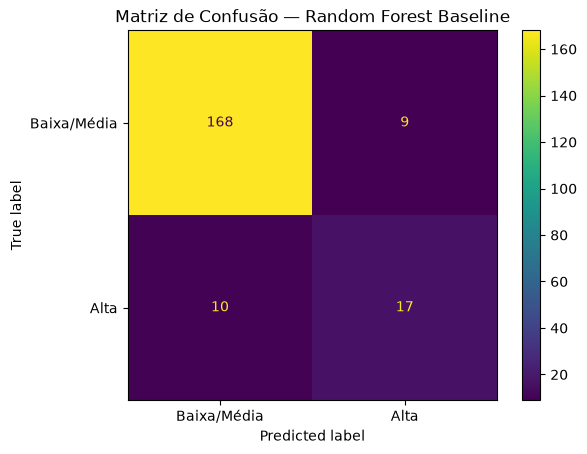

In [17]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Baixa/Média", "Alta"],
    values_format="d"
)

plt.title("Matriz de Confusão — Random Forest Baseline")
plt.show()

# Análises
As primeiras métricas e a matriz de confusão já nos indica que estamos proporcionalmente acertando menos nos vinhos com qualidade alta do que nos vinhos com qualidade média/baixa, considerando que é uma base desbalanceada, são poucos vinhos de alta qualidade para muitos de baixa/média.

Para o problema precisamos identificar principalmente o recall da classe Alta qualidade, que ficou 0,63.

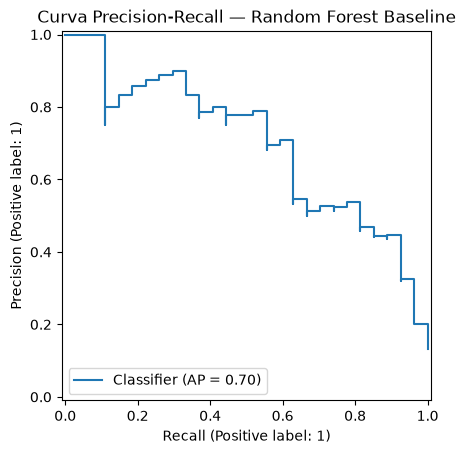

In [18]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_proba
)

plt.title("Curva Precision-Recall — Random Forest Baseline")
plt.show()

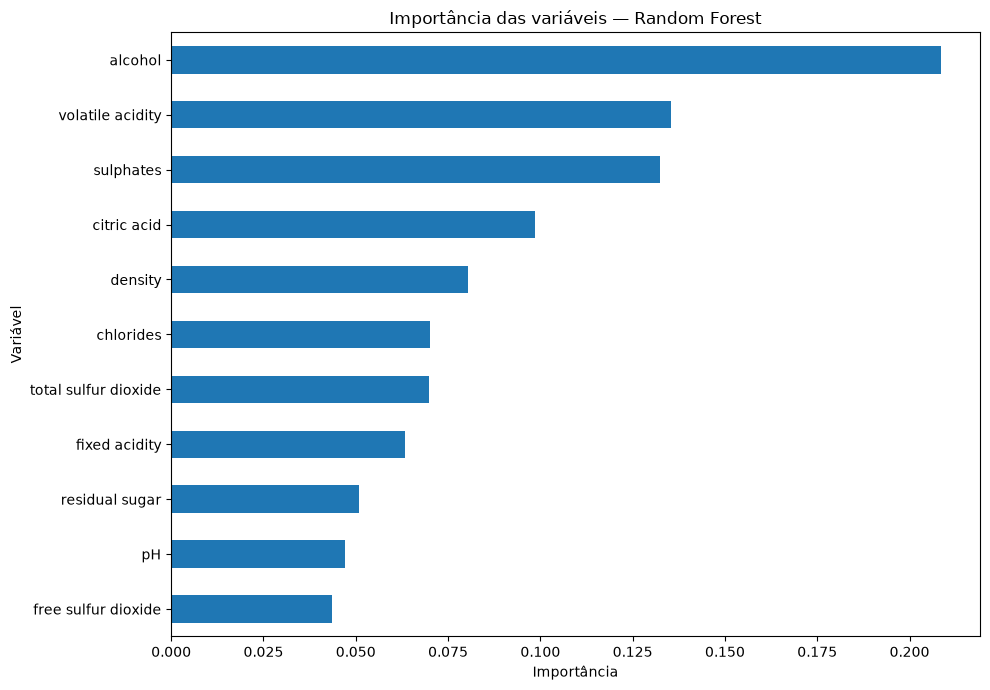

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

importancias = pd.Series(
    rf_baseline.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

importancias.plot(kind="barh", figsize=(10, 7))
plt.title("Importância das variáveis — Random Forest")
plt.xlabel("Importância")
plt.ylabel("Variável")
plt.tight_layout()
plt.show()

# Continuação das análises

vemos que as três variáveis que mais influenciam na qualidade do vinho é o alcool, a acidez volátil, e os sulphatos. 
Lembrando que a importância indica quao a variável contribuiu para as divisões das árevores no modelo

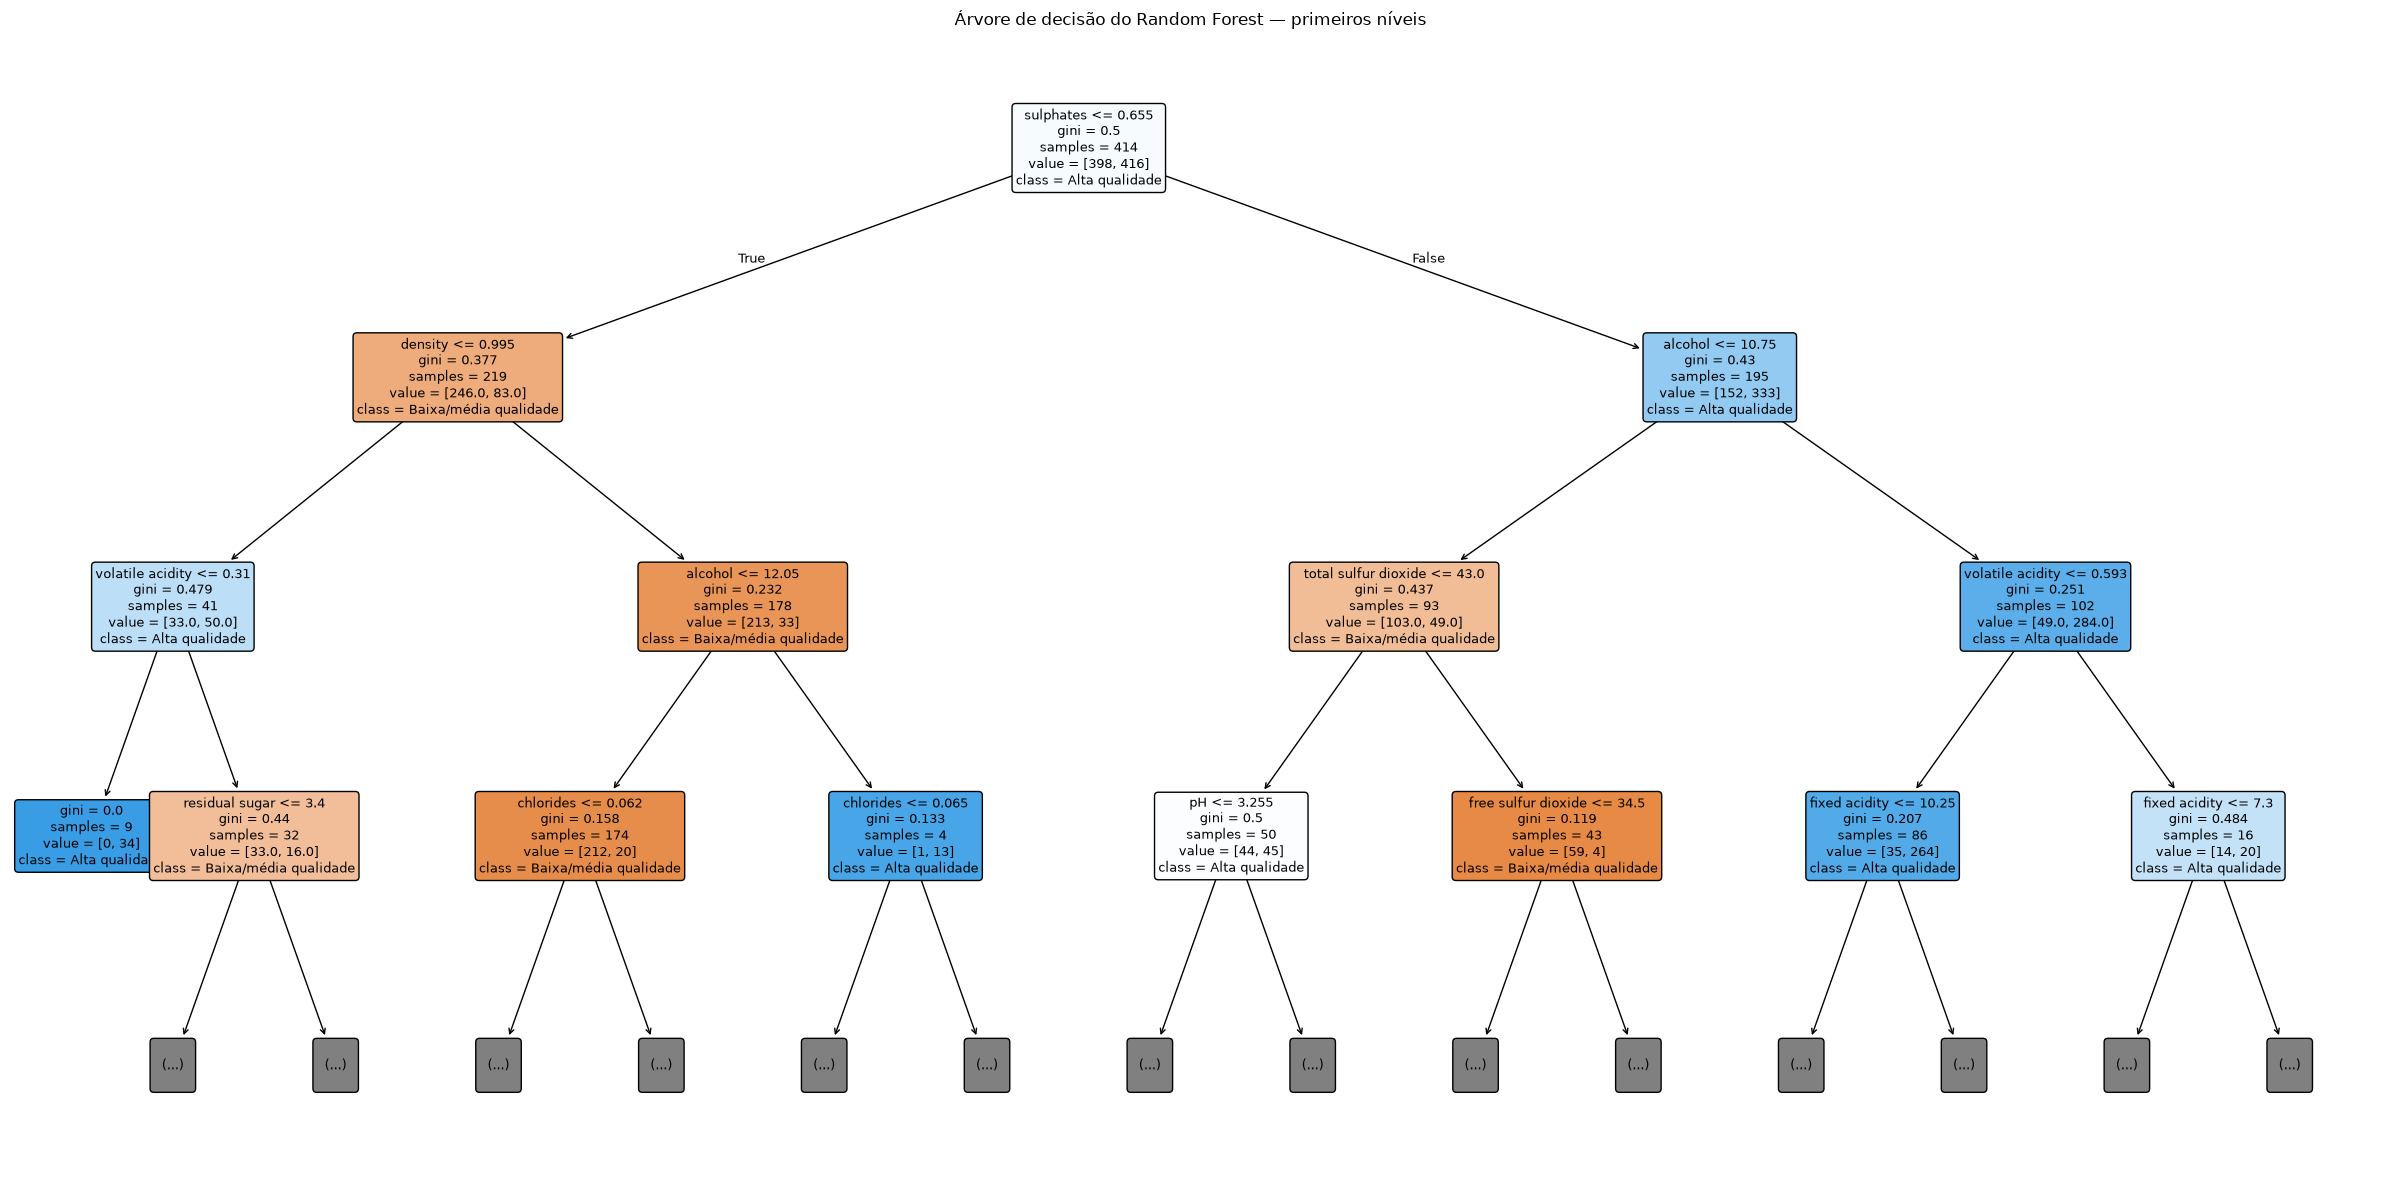

In [20]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Selecione a primeira árvore do Random Forest
arvore = rf_baseline.estimators_[0]

plt.figure(figsize=(24, 12))

plot_tree(
    arvore,
    feature_names=X_train.columns,
    class_names=["Baixa/média qualidade", "Alta qualidade"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Árvore de decisão do Random Forest — primeiros níveis")
plt.tight_layout()
plt.show()